# Model Selection Experiment

This notebook reports on an experiment to find out which kind of model is suitable for predicting whether an episode was successful.

In [1]:
# The notebook is not in the main folder of the project, so the imports need the working directory corrected.
import os

if "working_directory_corrected" not in vars():
    os.chdir("..")
    working_directory_corrected = True

import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from data.dataset import build_xy, load_episodes, split_off_test, split_train_validation
from evaluation.evaluation_metrics import EvaluationMetrics
from evaluation.multi_run_evaluation import MultiRunEvaluation
from models.majority_guessing_benchmark import MajorityGuessingBenchmark
from models.random_guessing_benchmark import RandomGuessingBenchmark

# 1) Experiment Setup

The candidates are:
1) Naive benchmarks: guessing a random class or always the majority class. They show which scores can be reached without learning anything.
2) Logistic regression: a simple linear model.
3) Random forest: many decision trees that vote. It can use combinations of features and does not need scaling.

## Evaluation metrics

76 % of the episodes are successful, so accuracy looks good even for a model that never finds a failure. I use:
- **accuracy**, because it is easy to understand
- **F1 score per class**, for "failure" and for "success". The failure score is the interesting one, finding failed episodes is the point of the model.
- **macro F1**, the mean of the two F1 scores, as the one number to compare models with

## Data loading

The data is prepared as described in the data preparation notebook.

In [2]:
X, y = build_xy(load_episodes())

X_rest, X_test, y_rest, y_test = split_off_test(X, y)
X_train, X_val, y_train, y_val = split_train_validation(X_rest, y_rest, seed=0)
X_train.shape, X_val.shape

((240, 66), (80, 66))

The test set is not used in this notebook. Models are compared on the validation set.

# 2) Results

## Benchmarks

These models do not learn from X, so only the validation scores are shown.

In [3]:
model = RandomGuessingBenchmark(seed=0)
model.fit(X=X_train, y=y_train)
EvaluationMetrics(y_true=y_val, y_pred=model.predict(X=X_val)).print_evaluation_report("Random Guessing - Validation Set")

Random Guessing - Validation Set
- accuracy: 0.62
- f1 failure: 0.44  f1 success: 0.72
- macro f1: 0.58
- confusion matrix (rows: true failure, true success):
[[12  8]
 [22 38]]


In [4]:
model = MajorityGuessingBenchmark()
model.fit(X=X_train, y=y_train)
EvaluationMetrics(y_true=y_val, y_pred=model.predict(X=X_val)).print_evaluation_report("Majority Guessing - Validation Set")

Majority Guessing - Validation Set
- accuracy: 0.75
- f1 failure: 0.0  f1 success: 0.86
- macro f1: 0.43
- confusion matrix (rows: true failure, true success):
[[ 0 20]
 [ 0 60]]


Majority guessing gets 75 % accuracy without finding a single failure, its failure F1 is 0. This is the reason accuracy is not the main metric.

Random guessing should be right about half of the time. Here it got 62 %, which is luck: the validation set has only 80 episodes, so a single run can be off by quite a bit. Something to keep in mind for the other results as well.

The score to beat is a macro F1 of 0.43 (majority) or about 0.5 (random).

## Logistic regression

The features have very different ranges (seconds, radians, standard deviations), so they are scaled first. The scaler is part of the pipeline, which means it is fitted on the training data only.

In [5]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

EvaluationMetrics(y_true=y_train, y_pred=model.predict(X_train)).print_evaluation_report("Logistic Regression - Training Set")
print()
EvaluationMetrics(y_true=y_val, y_pred=model.predict(X_val)).print_evaluation_report("Logistic Regression - Validation Set")

Logistic Regression - Training Set
- accuracy: 0.99
- f1 failure: 0.98  f1 success: 0.99
- macro f1: 0.99
- confusion matrix (rows: true failure, true success):
[[ 57   1]
 [  1 181]]

Logistic Regression - Validation Set
- accuracy: 0.86
- f1 failure: 0.74  f1 success: 0.91
- macro f1: 0.83
- confusion matrix (rows: true failure, true success):
[[16  4]
 [ 7 53]]


Logistic regression is clearly better than both benchmarks: macro F1 0.83 on the validation set, and it finds 16 of the 20 failures.

The training scores are much higher (0.99) than the validation scores, so the model overfits. With 66 features and only 240 training episodes that is not surprising.

## Random forest

In [6]:
model = RandomForestClassifier(n_estimators=100, random_state=0)
model.fit(X_train, y_train)

EvaluationMetrics(y_true=y_train, y_pred=model.predict(X_train)).print_evaluation_report("Random Forest - Training Set")
print()
EvaluationMetrics(y_true=y_val, y_pred=model.predict(X_val)).print_evaluation_report("Random Forest - Validation Set")

Random Forest - Training Set
- accuracy: 1.0
- f1 failure: 1.0  f1 success: 1.0
- macro f1: 1.0
- confusion matrix (rows: true failure, true success):
[[ 58   0]
 [  0 182]]

Random Forest - Validation Set
- accuracy: 0.93
- f1 failure: 0.87  f1 success: 0.95
- macro f1: 0.91
- confusion matrix (rows: true failure, true success):
[[20  0]
 [ 6 54]]


In [7]:
for max_depth in [2, 3, 5, None]:
    model = RandomForestClassifier(n_estimators=100, max_depth=max_depth, random_state=0)
    model.fit(X_train, y_train)
    train_f1 = EvaluationMetrics(y_true=y_train, y_pred=model.predict(X_train)).macro_f1
    val_f1 = EvaluationMetrics(y_true=y_val, y_pred=model.predict(X_val)).macro_f1
    print(f"max_depth={max_depth}: macro f1 train {train_f1:.2f}, validation {val_f1:.2f}")

max_depth=2: macro f1 train 0.96, validation 0.91
max_depth=3: macro f1 train 0.97, validation 0.91


max_depth=5: macro f1 train 1.00, validation 0.91


max_depth=None: macro f1 train 1.00, validation 0.91


The forest finds all 20 failures in the validation set and raises 6 false alarms (successful episodes it calls failed). Macro F1 is 0.91.

It fits the training data perfectly, so I tried limiting the depth of the trees. The training score goes down a little, the validation score stays at 0.91 for every depth. Even very small trees (depth 2) are enough, which suggests that a few features carry most of the information.

## Repeated runs

All results above come from one split, and 80 validation episodes are not many. To see how much the scores move, every model is trained 10 times. Each run uses a different train/validation split (and a different seed for the forest). The test set stays out of it.

In [8]:
NR_RUNS = 10


def create_logistic_regression(seed):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


def create_random_forest(seed):
    return RandomForestClassifier(n_estimators=100, random_state=seed)


evaluations = {
    "majority guessing": MultiRunEvaluation(lambda seed: MajorityGuessingBenchmark()),
    "logistic regression": MultiRunEvaluation(create_logistic_regression),
    "random forest": MultiRunEvaluation(create_random_forest),
}
for name, evaluation in evaluations.items():
    evaluation.evaluate(nr_runs=NR_RUNS, X=X_rest, y=y_rest)
    print(name)
    evaluation.print_metrics()
    print()

majority guessing
score               min    max   mean    std
macro_f1_train     0.43   0.43   0.43   0.00
macro_f1_val       0.43   0.43   0.43   0.00
f1_failure_val     0.00   0.00   0.00   0.00



logistic regression
score               min    max   mean    std
macro_f1_train     0.97   1.00   0.99   0.01
macro_f1_val       0.83   0.98   0.92   0.04
f1_failure_val     0.74   0.98   0.88   0.06



random forest
score               min    max   mean    std
macro_f1_train     1.00   1.00   1.00   0.00
macro_f1_val       0.91   0.98   0.94   0.02
f1_failure_val     0.87   0.97   0.91   0.03



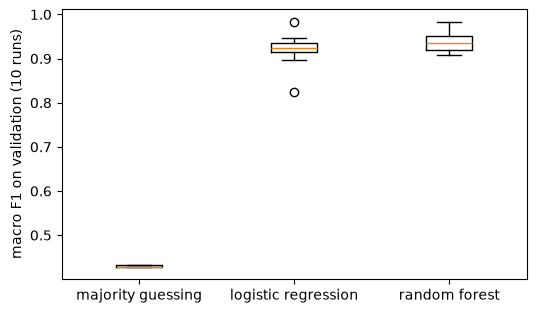

In [9]:
plt.figure(figsize=(6, 3.5))
plt.boxplot(
    [evaluation.get_validation_macro_f1s() for evaluation in evaluations.values()],
    tick_labels=list(evaluations.keys()),
)
plt.ylabel("macro F1 on validation (10 runs)")
plt.show()

The first split was not a typical one: 0.83 is the worst of the 10 logistic regression runs, its mean is 0.92. The gap to the forest that looked large above mostly disappears.

# 3) Discussion

Macro F1 on the validation data:

| model | first split | 10 runs (mean ± std) |
|---|---|---|
| majority guessing | 0.43 | 0.43 ± 0.00 |
| logistic regression | 0.83 | 0.92 ± 0.04 |
| random forest | 0.91 | 0.94 ± 0.02 |

Both learned models are far above the benchmark in every single run, so the joint data does contain information about success.

Between the two models the difference is small. The forest is a little better on average (0.94 against 0.92) and its scores move less between runs, but the difference is smaller than the spread of the logistic regression runs. From these numbers I can not claim that the forest is the better model in general.

Both models fit the training data almost perfectly and lose a few points on validation. More episodes would probably help more than a different model.

What I learned about the method: comparing models on one split of 80 episodes would have led me to a stronger conclusion than the data supports.

# 4) Conclusion

I continue with the random forest: slightly better scores, more stable, and it does not need scaling. Logistic regression would also have been a reasonable choice.